<a href="https://colab.research.google.com/github/Rose874-leo/iris-classification-ml/blob/main/titanic_survival_pediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
Shape: (891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   surviv

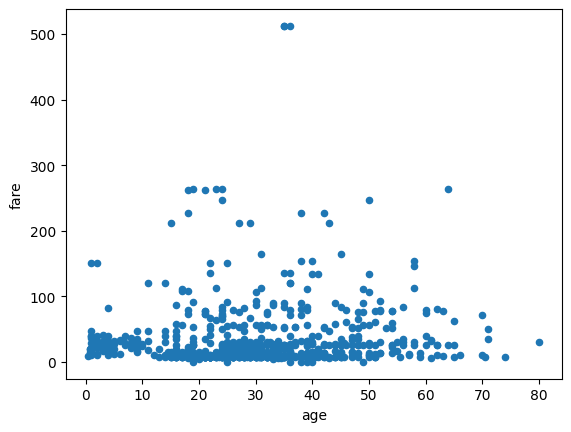

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64
Train size: (712, 10)
Test size: (179, 10)
Logistic Regression accuracy: 0.8100558659217877
Random Forest accuracy: 0.8044692737430168
Confusion Matrix:
[[89 16]
 [19 55]]

              precision    recall  f1-score   support

           0       0.82      0.85      0.84       105
           1       0.77      0.74      0.76        74

    accuracy                           0.80       179
   macro avg       0.80      0.80      0.80       179
weight

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df=sns.load_dataset("titanic")
print(df.head())
print("Shape:",df.shape)
print(df.info())
df.plot(kind="scatter",x="age", y="fare")
plt.show()
print(df.isnull().sum())
df = df.drop(columns=["deck"])
df["age"] = df["age"].fillna(df["age"].median())
df["embarked"] =df["embarked"].fillna(df["embarked"].mode()[0])
df["embark_town"] = df["embark_town"].fillna(df["embark_town"].mode()[0])
print(df.isnull().sum())
from sklearn.model_selection import train_test_split
features = ["pclass", "sex", "age","sibsp", "parch","fare","embarked"]
X = pd.get_dummies(df[features], columns=["sex" ,"embarked"])
y = df["survived"]
X_train, X_test, y_train,y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train size:" ,X_train.shape)
print("Test size:", X_test.shape)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
lr=LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
print("Logistic Regression accuracy:", accuracy_score(y_test, lr.predict(X_test)))
rf=RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
print("Random Forest accuracy:", accuracy_score(y_test, rf.predict(X_test)))
from sklearn.metrics import confusion_matrix, classification_report
y_pred =rf.predict(X_test)
print("Confusion Matrix:")
print(confusion_matrix(y_test,y_pred))
print()
print(classification_report(y_test,y_pred))
importances = pd.Series(rf.feature_importances_, index=X.columns)
print(importances.sort_values(ascending=False))